In [1]:
from data_utils import prepare_data, load_data

# Une seule fois
#prepare_data("Data/raw", "Data/processed")

In [2]:
# 1. Tout le million, en version réduite (1,9 Go)
#T, U, Y, targets = load_data("Data/processed", as_float=False)

#    puis, pour un lot donné, conversion en °C et en W au moment de l'utiliser
#t_batch = T[:256].float() / 100
#u_batch = U[:256].float()

# 2. Un sous-ensemble, directement en float32 (pour l'EDA ou les baselines)
#T, U, Y, targets = load_data("Data/processed", idx=range(50_000))

# 3. Tout le million en float32 (3,8 Go), seulement si la machine a assez de RAM
T, U, Y, targets = load_data("Data/processed")

Analyse de l'output 

In [3]:
import numpy as np 
import matplotlib.pyplot as plt 
import torch 
from matplotlib.collections import LineCollection

dt= 1.0 # 1 minute
N,L = T.shape
time= np.arange(L)*dt/60 # en heures 
targets =[str(t) for t in targets]
units =["W/K" , "W/K" ,"W/K" , "h" , "h" , "h"]
col= {name: i for i,name in enumerate(targets)}


In [5]:
for name in targets:
    mean = T[:,col[name]].mean()
    std = T[:,col[name]].std()
    skew= (((T[:,col[name]]-mean)/std)**3).mean()
    print (name , "mean=%.2f std=%.2f skew=%.2f"%(mean,std,skew))

HLC mean=24.62 std=0.00 skew=1.00
HLC_mit mean=24.65 std=0.08 skew=5.19
HLC_ext mean=24.67 std=0.15 skew=5.07
tau_b mean=24.69 std=0.23 skew=4.91
tau_n mean=24.71 std=0.28 skew=4.86
tau_inf mean=24.74 std=0.34 skew=4.81


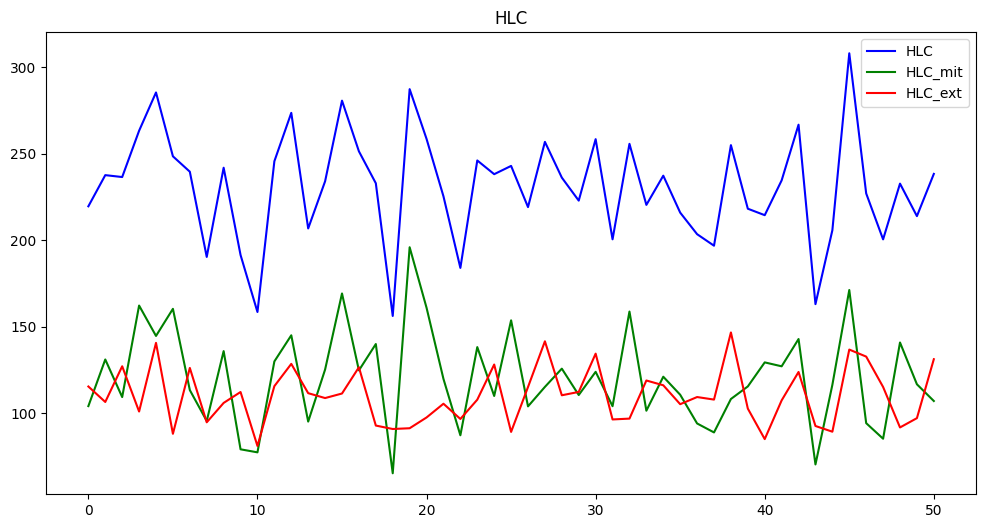

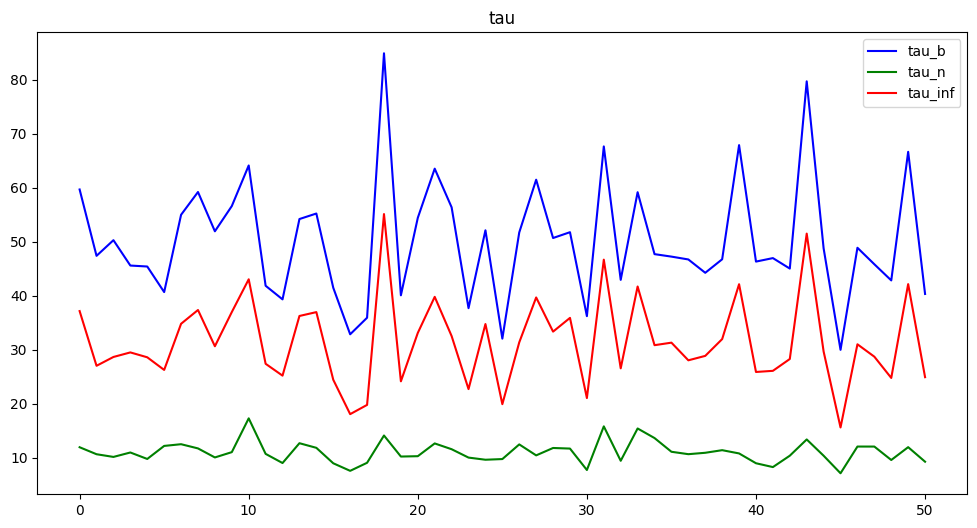

In [6]:
def plot_targets(names= targets ,start : int =0 , end : int=50 , title : str = "Targets"): 
    x = np.arange(start, end + 1)
    fig , ax = plt.subplots(figsize=(12,6))
    ax.plot(x , Y[start: end+1 , col[names[0]]]   , label=names[0] , color = 'blue')
    
    ax.plot(x ,  Y[start: end+1 , col[names[1]]]    , label= names[1] , color = 'green')
    ax.plot(x , Y[start: end+1 , col[names[2]]]   , label= names[2] , color= 'red')
    ax.legend()

    ax.set_title(title)
    plt.show()

plot_targets(targets[0:3], 0, 50 , "HLC")
plot_targets(targets[3:6], 0, 50 , "tau")

In [7]:
ecart =(Y[: , col['HLC']] - Y[: , col['HLC_mit']]- Y[: , col['HLC_ext']]).abs().max()
print( "Vérification de l'écart: " , ecart)
taub, taun, tauinf =Y[:, col['tau_b']] , Y[: , col['tau_n']] , Y[: , col['tau_inf']]
print( "Vérification de l'ordre de temps de réponse: " , (taun<tauinf).sum().item()/N)
print( "Vérification de l'ordre de temps de réponse: " , (tauinf<taub).sum().item()/N)


Vérification de l'écart:  tensor(3.0518e-05)
Vérification de l'ordre de temps de réponse:  1.0
Vérification de l'ordre de temps de réponse:  1.0


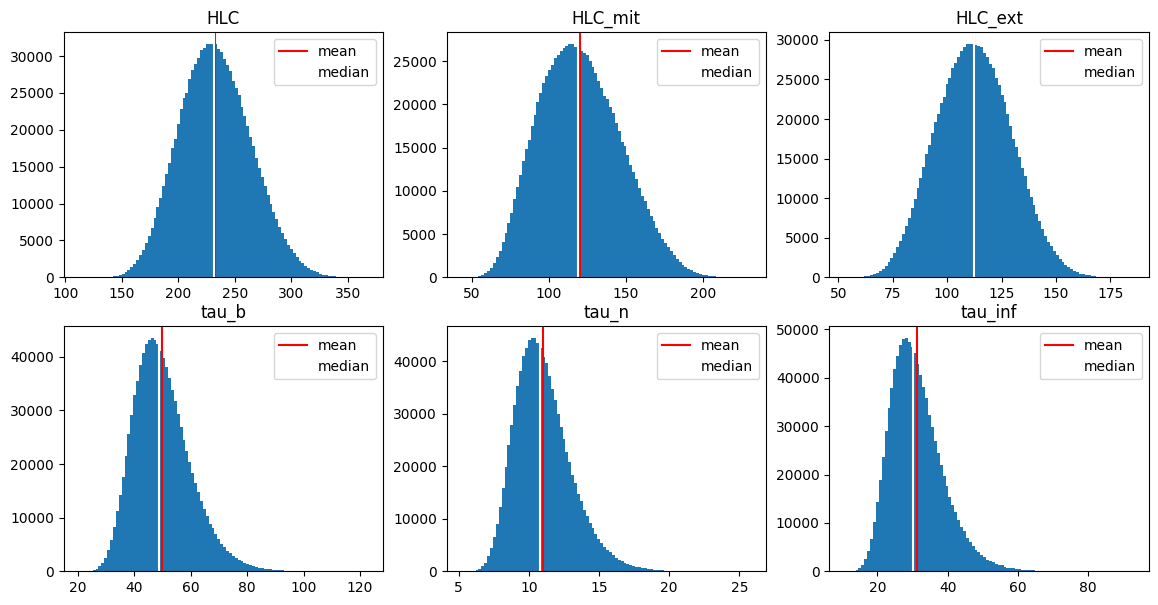

In [8]:
fig , axes = plt.subplots(2, 3 , figsize=(14, 7))
for ax , name in zip(axes.flatten() , targets):
    ax.hist(Y[: , col[name]] , bins=100)
    ax.set_title(name)
    ax.axvline(Y[: , col[name]].mean() , color='red' , label='mean')
    ax.axvline(np.median(Y[: , col[name]]) , color ='white' , label='median')
    ax.legend()
plt.show()    

Question : est ce que les jumeaux sont tous differents ? 

In [9]:
n_unique=torch.unique(Y , dim=0).shape[0]
print ("simulations à batiments distincts " , n_unique/N)

simulations à batiments distincts  1.0


Corrélation entre les cibles 

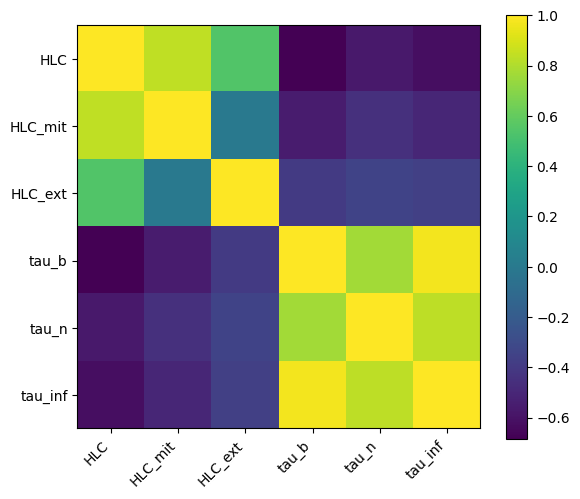

In [10]:
C= torch.corrcoef(Y.T)
fig, ax = plt.subplots(figsize= (6.5 , 5.5))
im = ax.imshow(C.numpy())

ax.set_xticks(range(len(targets)), targets, rotation=45, ha="right")
ax.set_yticks(range(len(targets)), targets)

plt.colorbar(im , ax=ax)
plt.show()

Les excitations

la nature du signal 

In [11]:
P_MAX = U.max().item()
is_binary = ((U == 0) | (U == P_MAX)).all(dim=1)
n_other = ((U != 0) & (U != P_MAX)).sum().item()

print(f"Puissance maximale                : {P_MAX:.0f} W")
print(f"Signaux tout-ou-rien (0 / Pmax)   : {is_binary.sum().item()} / {N}")
print(f"Valeurs de U autres que 0 et Pmax : {n_other}")

Puissance maximale                : 7000 W
Signaux tout-ou-rien (0 / Pmax)   : 1000000 / 1000000
Valeurs de U autres que 0 et Pmax : 0


Extraction des caractéristiques de l'excitation 

In [12]:
import torch 
print(f"min U = {U.min().item():.0f} W | max U = {U.max().item():.0f} W")   # attendu : 0 et 7000

min U = 0 W | max U = 7000 W


In [13]:
T_AXIS = torch.from_numpy(time).float()
def excitation_descriptors(u: torch.Tensor) -> dict[str, torch.Tensor]:
    """Résume chaque signal U(t) d'un lot de simulations en quelques grandeurs."""
    u = u.float()
    du = u.diff(dim=1)                   # +7000 à un allumage, -7000 à une extinction, 0 sinon
    energy = u.sum(1) * dt             # Wh
    n_on = (u > 0).sum(1)                # nombre de minutes où U est non nul    n_blocks = (du > 0).sum(1) + (u[:, 0] > 0)

    first_on = u.argmax(1) * dt        # premier instant où U atteint son maximum
    first_on[n_on == 0] = float("nan")
    n_blocks = (du > 0).sum(1) + (u[:, 0] > 0)
    return {
        "energie_kWh":        energy / 1000,
        "taux_allumage":      n_on / L,
        "n_commutations":     (du != 0).sum(1).float(),
        "n_creneaux_on":      n_blocks,
        "duree_on_moy_h":     n_on * dt / n_blocks,
        "premier_allumage_h": first_on,
        "instant_moyen_h":    (u @ T_AXIS) / u.sum(1),
    }


parts = [excitation_descriptors(U[a:a + 50_000]) for a in range(0, N, 50_000)]
desc = {name: torch.cat([p[name] for p in parts]) for name in parts[0]}
del parts

In [14]:
print(f"{'':22s}{'valides':>9s}{'moyenne':>10s}{'écart-type':>12s}{'min':>9s}{'médiane':>10s}{'max':>9s}")
for name, c in desc.items():
    c = c[~c.isnan()].double()          # on ignore les NaN (descripteur non défini)
    print(f"{name:22s}{len(c):9d}{c.mean().item():10.2f}{c.std().item():12.2f}"
          f"{c.min().item():9.2f}{c.median().item():10.2f}{c.max().item():9.2f}")

                        valides   moyenne  écart-type      min   médiane      max
energie_kWh             1000000   1574.75      821.19     0.00   1799.00  3360.00
taux_allumage           1000000      0.47        0.24     0.00      0.54     1.00
n_commutations          1000000      6.18       21.79     0.00      2.00   240.00
n_creneaux_on           1000000      3.34       10.88     0.00      1.00   120.00
duree_on_moy_h           915836    193.37      124.94     1.00    186.50   480.00
premier_allumage_h       915836    118.51      100.58     0.00     98.00   479.00
instant_moyen_h          915836      4.51        1.15     2.00      4.43     7.98


Cas particuliers

In [15]:
no_exc = desc["energie_kWh"] == 0
always_on = desc["taux_allumage"] == 1
single = (desc["n_creneaux_on"] == 1) & ~always_on
late = desc["premier_allumage_h"] >= 7
fast = desc["n_commutations"] > 100

for name, mask in [("Sans excitation", no_exc), ("Toujours allumé", always_on),
                   ("Un seul créneau", single), ("Chauffe seulement en fin (>= 7 h)", late),
                   ("Créneaux rapides (> 100 commutations)", fast)]:
    print(f"{name:40s}{mask.sum().item():9d}  ({mask.float().mean().item():6.2%})")

Sans excitation                             84164  ( 8.42%)
Toujours allumé                              8711  ( 0.87%)
Un seul créneau                            602905  (60.29%)
Chauffe seulement en fin (>= 7 h)          861151  (86.12%)
Créneaux rapides (> 100 commutations)       14429  ( 1.44%)


Les distributions 

Configurations 

In [4]:
import copy
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"          # calcul en demi-précision sur GPU (plus rapide)
P_MAX = 7000.0

Train test split 

In [ ]:
split_file = "Data/processed/splits.pt"

# Sous-groupes : gardés, car l'évaluation en a besoin (1 Mo chacun)
NO_EXC = U.sum(1) == 0
ALWAYS_ON = (U == P_MAX).all(1)

try:
    SPLITS = torch.load(split_file)
except FileNotFoundError:
    group = NO_EXC.long() + 2 * ALWAYS_ON.long()      # 0 = PRBS, 1 = sans excitation, 2 = toujours allumé
    g = torch.Generator().manual_seed(SEED)
    parts = {"train": [], "val": [], "test": []}
    for k in group.unique():
        idx = (group == k).nonzero().squeeze(1)
        idx = idx[torch.randperm(len(idx), generator=g)]
        n = len(idx) // 10
        parts["test"].append(idx[:n])
        parts["val"].append(idx[n:2 * n])
        parts["train"].append(idx[2 * n:])
    # Mélange final : sinon les indices restent rangés par groupe
    SPLITS = {name: (idx := torch.cat(p))[torch.randperm(len(idx), generator=g)]
              for name, p in parts.items()}
    torch.save(SPLITS, split_file)
    del group, parts

print({k: len(v) for k, v in SPLITS.items()})

{'train': 800002, 'val': 99999, 'test': 99999}


In [6]:
CLASSES = {
    "PRBS": ~NO_EXC & ~ALWAYS_ON,
    "Sans excitation": NO_EXC,
    "Toujours allumé": ALWAYS_ON,
}

print(f"{'':8s}{'taille':>10s}" + "".join(f"{c:>20s}" for c in CLASSES))
for split, idx in SPLITS.items():
    cells = "".join(f"{m[idx].sum().item():>10d} ({m[idx].float().mean().item():6.2%})"
                    for m in CLASSES.values())
    print(f"{split:8s}{len(idx):10d}{cells}")

            taille                PRBS     Sans excitation     Toujours allumé
train       800002    725701 (90.71%)     67332 ( 8.42%)      6969 ( 0.87%)
val          99999     90712 (90.71%)      8416 ( 8.42%)       871 ( 0.87%)
test         99999     90712 (90.71%)      8416 ( 8.42%)       871 ( 0.87%)


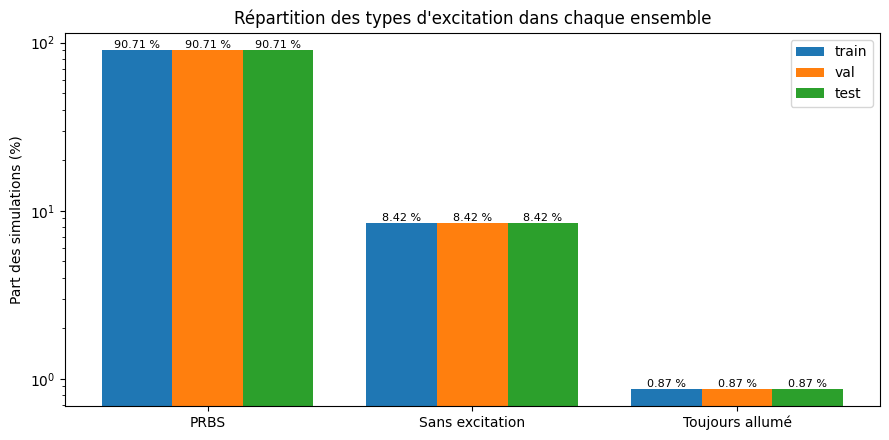

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(CLASSES))
width = 0.8 / len(SPLITS)

for k, (split, idx) in enumerate(SPLITS.items()):
    props = [100 * m[idx].float().mean().item() for m in CLASSES.values()]
    bars = ax.bar(x + k * width, props, width, label=split)
    ax.bar_label(bars, fmt="%.2f %%", fontsize=8)

ax.set_xticks(x + width * (len(SPLITS) - 1) / 2, list(CLASSES))
ax.set_ylabel("Part des simulations (%)")
ax.set_yscale("log")                      # pour voir aussi la petite classe « toujours allumé »
ax.set_title("Répartition des types d'excitation dans chaque ensemble")
ax.legend()
plt.tight_layout()
plt.show()

Normalisation 

In [10]:
import copy
import torch 
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", DEVICE)

targets = [str(t) for t in targets]
col = {name: i for i, name in enumerate(targets)}
N, L = T.shape
P_MAX = 7000.0
NO_EXC = U.sum(1) == 0
ALWAYS_ON = (U == P_MAX).all(1)

Appareil : cpu


In [ ]:
SPLITS = torch.load("Data/processed/splits.pt")
train = SPLITS["train"]

# Moyenne et écart-type de T sur tout le train, calculés par morceaux
T_SD, T_MU = torch.std_mean(T[SPLITS["train"][:100000]])
T_MU, T_SD = T_MU.item(), T_SD.item()
print(f"T (100 000 simulations du train) : moyenne = {T_MU:.3f} °C, écart-type = {T_SD:.3f} °C")
print(f"T (train) : moyenne = {T_MU:.3f} °C, écart-type = {T_SD:.3f} °C")

T (100 000 simulations du train) : moyenne = 30.560 °C, écart-type = 4.788 °C
T (train) : moyenne = 30.560 °C, écart-type = 4.788 °C


In [7]:

def encode_targets(y: torch.Tensor) -> torch.Tensor:
    """Indicateurs (n, 6) -> latent contraint (n, 5)."""
    tb, tn, ti = y[:, col["tau_b"]], y[:, col["tau_n"]], y[:, col["tau_inf"]]
    return torch.stack([y[:, col["HLC_mit"]], y[:, col["HLC_ext"]],
                        tn.log(), (ti - tn).log(), (tb - ti).log()], dim=1)


def decode_targets(z: torch.Tensor) -> torch.Tensor:
    """Latent (n, 5) -> indicateurs (n, 6), contraintes garanties."""
    tn = z[:, 2].exp()
    ti = tn + z[:, 3].exp()
    tb = ti + z[:, 4].exp()
    y = torch.empty(len(z), 6, dtype=z.dtype, device=z.device)
    y[:, col["HLC_mit"]], y[:, col["HLC_ext"]] = z[:, 0], z[:, 1]
    y[:, col["HLC"]] = z[:, 0] + z[:, 1]
    y[:, col["tau_n"]], y[:, col["tau_inf"]], y[:, col["tau_b"]] = tn, ti, tb
    return y


Z = encode_targets(Y.double()).float()
Z_MU, Z_SD = Z[train].mean(0), Z[train].std(0)
Z_STD = (Z - Z_MU) / Z_SD                      # ce que le réseau apprend à prédire



In [8]:
from torch.utils.data import DataLoader, Dataset


class MyDataset(Dataset):
    """Simulations thermiques : renvoie UNE simulation à la fois."""

    def __init__(self, idx: torch.Tensor, noise_c: float = 0.0) -> None:
        self.idx = idx              # numéros des simulations de cet ensemble
        self.noise_c = noise_c      # bruit de capteur (°C), 0 = aucun

    def __len__(self) -> int:
        return len(self.idx)        # nombre de simulations dans l'ensemble

    def __getitem__(self, i: int) -> tuple[torch.Tensor, torch.Tensor]:
        sim = self.idx[i]           # numéro de la i-ème simulation de l'ensemble
        t = T[sim]
        if self.noise_c > 0:
            t = t + self.noise_c * torch.randn_like(t)
        x = torch.stack([(t - T_MU) / T_SD, U[sim] / P_MAX])   # (2, L)
        return x, Z_STD[sim]                                    # (2, L), (5,)


# 1. Les instances de Dataset
train_dataset = MyDataset(SPLITS["train"])
val_dataset = MyDataset(SPLITS["val"])

# 2. Les instances de DataLoader, avec les paramètres des batchs
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=1024, shuffle=False)

x, z = next(iter(train_loader))
print(x.shape, z.shape)     # torch.Size([256, 2, 480]) torch.Size([256, 5])

torch.Size([256, 2, 480]) torch.Size([256, 5])


La baseline : Moyenne 

In [11]:
def regression_metrics(y_true: torch.Tensor, y_pred: torch.Tensor) -> dict:
    """RMSE, MAE, P95, MAPE et R² par indicateur, en unités physiques."""
    out = {}
    for name in targets:
        t, p = y_true[:, col[name]].double(), y_pred[:, col[name]].double()
        err = p - t
        out[name] = {"RMSE": err.pow(2).mean().sqrt().item(),
                     "MAE": err.abs().mean().item(),
                     "P95": err.abs().quantile(0.95).item(),
                     "MAPE": 100 * (err / t).abs().mean().item(),
                     "R2": (1 - err.pow(2).sum() / (t - t.mean()).pow(2).sum()).item()}
    return out


RESULTS = {}


def evaluate(name: str, y_pred: torch.Tensor, split: str = "val") -> None:
    """Évalue un modèle : globalement, avec et sans excitation."""
    idx = SPLITS[split]
    y_true, no_exc = Y[idx], NO_EXC[idx]
    RESULTS[name] = {g: regression_metrics(y_true[m], y_pred[m])
                     for g, m in [("tout", torch.ones_like(no_exc)),
                                  ("avec excitation", ~no_exc), ("sans excitation", no_exc)]}
    print(f"=== {name} ({split}) ===")
    print(f"{'':12s}{'RMSE':>9s}{'MAE':>9s}{'P95':>9s}{'MAPE %':>9s}{'R²':>8s}{'R² exc.':>9s}")
    for t in targets:
        m, me = RESULTS[name]["tout"][t], RESULTS[name]["avec excitation"][t]
        print(f"{t:12s}{m['RMSE']:9.2f}{m['MAE']:9.2f}{m['P95']:9.2f}"
              f"{m['MAPE']:9.2f}{m['R2']:8.3f}{me['R2']:9.3f}")


# Baseline : prédire la moyenne du train pour chaque indicateur
evaluate("Moyenne", Y[SPLITS["train"]].mean(0).expand(len(SPLITS["val"]), -1))

=== Moyenne (val) ===
                 RMSE      MAE      P95   MAPE %      R²  R² exc.
HLC             31.41    25.35    60.67    11.19  -0.000   -0.000
HLC_mit         26.26    21.41    49.59    19.01  -0.000   -0.000
HLC_ext         17.12    13.87    32.90    12.87  -0.000   -0.000
tau_b           10.16     8.00    19.43    16.48  -0.000   -0.000
tau_n            2.02     1.58     3.89    14.60  -0.000   -0.000
tau_inf          7.58     5.93    14.42    19.80  -0.000   -0.000


Le modèle TCN

In [12]:
class ResidualBlock(nn.Module):
    """Deux convolutions dilatées + connexion résiduelle."""

    def __init__(self, channels: int, kernel: int, dilation: int, dropout: float) -> None:
        super().__init__()
        pad = (kernel - 1) * dilation // 2           # garde la longueur de la séquence
        self.net = nn.Sequential(
            nn.Conv1d(channels, channels, kernel, padding=pad, dilation=dilation),
            nn.BatchNorm1d(channels), nn.GELU(), nn.Dropout(dropout),
            nn.Conv1d(channels, channels, kernel, padding=pad, dilation=dilation),
            nn.BatchNorm1d(channels),
        )
        self.act = nn.GELU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.act(x + self.net(x))


class TCNRegressor(nn.Module):
    """TCN : séquence (B, 2, L) -> latent standardisé (B, 5)."""

    def __init__(self, in_channels: int = 2, channels: int = 64, kernel: int = 5,
                 n_levels: int = 7, dropout: float = 0.1, n_out: int = 5) -> None:
        super().__init__()
        self.stem = nn.Conv1d(in_channels, channels, kernel_size=1)
        self.blocks = nn.Sequential(*[ResidualBlock(channels, kernel, 2 ** i, dropout)
                                      for i in range(n_levels)])
        self.head = nn.Sequential(nn.Linear(2 * channels, channels), nn.GELU(),
                                  nn.Dropout(dropout), nn.Linear(channels, n_out))
        self.receptive_field = 1 + 2 * (kernel - 1) * (2 ** n_levels - 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.blocks(self.stem(x))                       # (B, channels, L)
        h = torch.cat([h.mean(-1), h.amax(-1)], dim=1)      # résumé de toute la séquence
        return self.head(h)


model = TCNRegressor()
print(f"Paramètres : {sum(p.numel() for p in model.parameters()):,}")
print(f"Champ réceptif : {model.receptive_field} pas de temps (séquence : {L})")

Paramètres : 298,181
Champ réceptif : 1017 pas de temps (séquence : 480)


Entraînement

In [13]:
tiny = MyDataset(SPLITS["train"][:256])
x, z = next(iter(DataLoader(tiny, batch_size=256)))
x, z = x.to(DEVICE), z.to(DEVICE)

m = TCNRegressor().to(DEVICE)
opt = torch.optim.Adam(m.parameters(), lr=1e-3)
criterion = nn.MSELoss()
m.train()
for step in range(300):
    opt.zero_grad()
    loss = criterion(m(x), z)
    loss.backward()
    opt.step()
    if step % 50 == 0:
        print(f"Étape {step:3d} : perte = {loss.item():.4f}")

Étape   0 : perte = 2.8229
Étape  50 : perte = 0.7049
Étape 100 : perte = 0.4556
Étape 150 : perte = 0.3024
Étape 200 : perte = 0.2201
Étape 250 : perte = 0.1856


In [14]:
model = TCNRegressor(in_channels=2, channels=64, kernel=5, n_levels=7, dropout=0.1, n_out=5)
def weights_init(layer_in):
    if isinstance(layer_in, (nn.Linear, nn.Conv1d)):
        nn.init.kaiming_uniform_(layer_in.weight)
        layer_in.bias.data.fill_(0.0)

model.apply(weights_init)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.5)

model.to(DEVICE)

n_epochs = 10
best_val, best_state = float("inf"), None
history = []


In [15]:

# loop over the dataset n_epochs times
for epoch in range(n_epochs):
    model.train()                                   #  mode entraînement (dropout, BatchNorm)
    epoch_loss = 0.0
    # loop over batches
    for i, data in enumerate(train_loader):
        # retrieve inputs and labels for this batch
        x_batch, y_batch = data
        x_batch, y_batch = x_batch.to(DEVICE), y_batch.to(DEVICE)
        # zero the parameter gradients
        optimizer.zero_grad()
        # forward pass
        pred = model(x_batch)
        loss = criterion(pred, y_batch)
        # backward pass
        loss.backward()
        # parameter update
        optimizer.step()
        # update statistics
        epoch_loss += loss.item()
    epoch_loss /= len(train_loader)                 # perte moyenne par batch

    #  validation : on mesure l'erreur sur des simulations jamais vues
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            pred = model(x_batch.to(DEVICE))
            val_loss += criterion(pred, y_batch.to(DEVICE)).item()
    val_loss /= len(val_loader)

    # print error
    print(f"Epoch {epoch:5d}, train loss {epoch_loss:.4f}, val loss {val_loss:.4f}, "
          f"lr {scheduler.get_last_lr()[0]:.1e}")
    history.append({"epoch": epoch + 1, "train": epoch_loss, "val": val_loss})

    #  on garde le meilleur modèle sur la validation
    if val_loss < best_val:
        best_val = val_loss
        best_state = copy.deepcopy(model.state_dict())

    # tell scheduler to consider updating learning rate
    scheduler.step()

model.load_state_dict(best_state)                   #  retour au meilleur modèle
#torch.save(model.state_dict(), "tcn.pt")


KeyboardInterrupt: 

In [ ]:
epochs = [h["epoch"] for h in history]
train_losses = [h["train"] for h in history]
val_losses = [h["val"] for h in history]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(epochs, train_losses, marker="o", label="entraînement")
ax.plot(epochs, val_losses, marker="o", label="validation")
ax.set_yscale("log")
ax.set_xlabel("Époque")
ax.set_ylabel("MSE (latent standardisé)")
ax.set_title("TCN — courbes d'apprentissage")
ax.legend()
plt.show()

best = min(history, key=lambda h: h["val"])
print(f"Meilleure validation : {best['val']:.4f} à l'époque {best['epoch']}")